# STEP 8. Prediction model + temporal-split validation

The **core question** here is a prediction question: *which food-service categories will turn into a net decline next quarter, by district?*

If STEPs 6 and 7 answered **why**, this step prepares to answer **what**.

## Temporal split

| Purpose | Feature quarter | Target quarter | Label |
|---|---|---|---|
| Training | `TRAIN_QUARTERS` 20231~20253 | 20232~20254 | Yes |
| Validation | `VALID_Q` 20254 | **20261** | Yes |
| Prediction | `SCORE_Q` 20261 | **20262** | No (STEP 9) |

The validation set is scored on the **actual** openings and closures of 20261, so it is an evaluation that imitates a real future prediction.

## Why accuracy is not used as the metric

The positive rate is 25%. **Predicting "no net decline" for everything alone gives 75% accuracy.** So the following are used instead.

| Metric | Meaning | Reference |
|---|---|---|
| **AUC** | Probability that a randomly drawn positive gets a higher score than a negative | 0.5 = random, 0.7 = useful |
| **PR-AUC** | Performance focused on positives. **The positive rate (0.26) is the random baseline** | How far above the baseline |
| **Brier** | Mean squared error of the probability forecast | **Lower is better** |
| **Calibration** | "Of the cells given 30%, do 30% actually occur?" | Essential for ranking |

## Procedure

8-1 Split and leakage check → 8-2 Features → 8-3 Baselines → 8-4 Models → 8-5 Rolling origin → 8-6 Calibration → **8-7 To what unit can we trust it?** → 8-8 Variable importance → 8-10 Save

In [1]:
import sys, os
from pathlib import Path

# Wherever the notebook is opened, find the project root and add it to sys.path
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# If the kernel is not restarted after editing config.py, Python caches the old module.
import importlib
if "config" in sys.modules:
    importlib.reload(sys.modules["config"])

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("Project root:", ROOT.name)

Project root: seoul-closure-risk


In [2]:
import pickle
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, log_loss, roc_curve)
from config import (PROC, FIG, RAW, FILES, ENCODING, TARGET_TYPE, SEED, standardize_source,
                    stable_rank, rank_order, tie_random_precision, tie_report,
                    TRAIN_QUARTERS, VALID_Q, SCORE_Q,
                    ROLLING_VALID, PRED_NUM, build_features, design_matrix,
                    set_plot_style)
set_plot_style()
OUT = FIG.parent

panel = build_features(pd.read_pickle(PROC / "03_panel.pkl"))
print(f"Panel {panel.shape}")
print(f"Training quarters {TRAIN_QUARTERS[0]}~{TRAIN_QUARTERS[-1]} ({len(TRAIN_QUARTERS)})")
print(f"Validation quarter {VALID_Q} (target {SCORE_Q})")

Panel (67475, 39)
Training quarters 20231~20253 (11)
Validation quarter 20254 (target 20261)


## 8-1. Split and leakage check

Leakage happens silently and makes results look better. So it is blocked in code.

In [3]:
tr = panel[panel["quarter_code"].isin(TRAIN_QUARTERS)].copy()
va = panel[panel["quarter_code"] == VALID_Q].copy()

assert VALID_Q not in TRAIN_QUARTERS,           "The validation quarter is in the training list"
assert tr["quarter_code"].max() < VALID_Q,   "Training contains quarters at or after the validation quarter"
assert len(tr) + len(va) == len(panel),         "The split sizes do not sum to the total"
print("✅ Leakage check passed")
print(f"  Training {len(tr):,} rows  positive rate {tr['y'].mean():.1%}")
print(f"  Validation {len(va):,} rows  positive rate {va['y'].mean():.1%}")
print(f"\nNote: the positive rate should be similar in training and validation to conclude there is no distribution shift.")

✅ Leakage check passed
  Training 61,996 rows  positive rate 25.4%
  Validation 5,479 rows  positive rate 26.0%

Note: the positive rate should be similar in training and validation to conclude there is no distribution shift.


## 8-2. Features

Uses `config.build_features` / `config.design_matrix`. **STEP 9 calls the same functions, so training and prediction cannot drift apart.**

### Why quarter dummies are not included

The propensity-score and explanatory models in STEPs 6 and 7 included quarter dummies. That was **explanation**, so using them only within the training quarters was enough.

Prediction is different. The prediction target is 20261, a quarter absent from training, so a dummy cannot be built, and if built it would be all 0. The honest position is that **the seasonal effect of a future quarter cannot be known**.

### Newly added: current momentum

`opening_rate`, `closure_rate`, `net_change_rate` and `net_decline_now` are **values at the feature quarter**, so they are not leakage. They let the model use "the probability that a cell that is already shrinking now keeps shrinking next quarter".

In [4]:
Xtr = design_matrix(tr)
COLS = list(Xtr.columns)
Xva  = design_matrix(va, COLS)
ytr, yva = tr["y"].to_numpy(), va["y"].to_numpy()

MED = Xtr.median()                     # Imputation values for the linear model (computed on training only)
Xtr_i, Xva_i = Xtr.fillna(MED), Xva.fillna(MED)

print(f"{len(COLS)} features = {len(PRED_NUM)} numeric + {len(COLS)-len(PRED_NUM)} dummy")
print(f"  Features with missing values : {[c for c in COLS if Xtr[c].isna().any()]}")
print(f"\nValidation design-matrix columns match : {list(Xva.columns) == COLS}")

51 features = 12 numeric + 39 dummy
  Features with missing values : ['log_sales_per_store']

Validation design-matrix columns match : True


## 8-3. Baselines

**Whether a model is good can only be known by comparing it with baselines.** Three are set.

| | Rule |
|---|---|
| A | Always the training mean probability (uses no information) |
| B | The previous quarter's state carried over (if shrinking now, it will shrink next time too) |
| C | Mean net-decline rate over the training period, by service category |

In [5]:
def evaluate(name, p, y=yva):
    return {"model_name": name,
            "AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p),
            "LogLoss": log_loss(y, np.clip(p, 1e-6, 1-1e-6))}

rows = [
    evaluate("A always average",   np.full(len(yva), ytr.mean())),
    evaluate("B previous-quarter status", np.where(va["net_decline_now"] == 1, 0.60, 0.15)),
    evaluate("C service-category average",   va["service_name"]
                              .map(tr.groupby("service_name")["y"].mean()).to_numpy()),
    # Store-count rule: a ranking rule that treats cells with more stores as riskier. It is a score, not a probability, so Brier and LogLoss are not computed.
    {"model_name": "Rule: store count",
     "AUC": roc_auc_score(yva, va["store_count"].to_numpy().astype(float)),
     "PR-AUC": average_precision_score(yva, va["store_count"].to_numpy().astype(float)),
     "Brier": np.nan, "LogLoss": np.nan},
]
display(pd.DataFrame(rows).round(4))
print(f"Note: random baseline of PR-AUC = validation positive rate {yva.mean():.4f}")

,model_name,AUC,PR-AUC,Brier,LogLoss
0,A always average,0.5000,0.2597,0.1923,0.5728
1,B previous-quarter status,0.5315,0.2742,0.2178,0.6336
2,C service-category average,0.5543,0.2910,0.1912,0.5699
3,Rule: store count,0.6540,0.3879,NaN,NaN


Note: random baseline of PR-AUC = validation positive rate 0.2597


## 8-4. Models

- **Logistic** - linear. Easy to interpret and tends to be well calibrated
- **Boosting** (HistGradientBoosting) - captures nonlinearity and interactions. Handles missing values as is
- **Random forest** - for comparison

In [6]:
logit = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=3000, C=1.0, random_state=SEED))
logit.fit(Xtr_i, ytr)

hgb = HistGradientBoostingClassifier(
    max_iter=400, learning_rate=0.06, max_leaf_nodes=31,
    l2_regularization=1.0, random_state=SEED).fit(Xtr, ytr)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                            n_jobs=-1, random_state=SEED).fit(Xtr_i, ytr)

preds = {"D logistic": logit.predict_proba(Xva_i)[:, 1],
         "E boosting":   hgb.predict_proba(Xva)[:, 1],
         "F random forest": rf.predict_proba(Xva_i)[:, 1]}
rows += [evaluate(k, v) for k, v in preds.items()]

board = pd.DataFrame(rows).set_index("model_name")
display(board.round(4))

BEST = board["PR-AUC"].idxmax()
print(f"→ Best by PR-AUC : {BEST}")
print(f"   PR-AUC vs baseline {board.loc[BEST,'PR-AUC']:.3f} vs {yva.mean():.3f} "
      f"({board.loc[BEST,'PR-AUC']/yva.mean():.2f}x)")

,AUC,PR-AUC,Brier,LogLoss
model_name,,,,
A always average,0.5000,0.2597,0.1923,0.5728
B previous-quarter status,0.5315,0.2742,0.2178,0.6336
C service-category average,0.5543,0.2910,0.1912,0.5699
Rule: store count,0.6540,0.3879,NaN,NaN
D logistic,0.6695,0.4067,0.1796,0.5400
E boosting,0.6687,0.4179,0.1789,0.5389
F random forest,0.6625,0.4125,0.1798,0.5411


→ Best by PR-AUC : E boosting
   PR-AUC vs baseline 0.418 vs 0.260 (1.61x)


In [7]:
print("⚠️ The table above is performance on the 'validation' quarter. The model was chosen by looking at it, so")
print("   it is biased optimistically. For an unbiased estimate use the 8-5 rolling validation.")

⚠️ The table above is performance on the 'validation' quarter. The model was chosen by looking at it, so
   it is biased optimistically. For an unbiased estimate use the 8-5 rolling validation.


## 8-4b. External baseline - the Seoul official commercial-area change indicator ★

All baselines so far were **built by us**. Only by comparing against a judgment tool actually used in practice is there a "reason to adopt this model".

The Seoul commercial-area analysis service assigns each commercial area a quarterly **commercial-area change indicator (HH, HL, LH, LL)**. Here we check whether the **HL = commercial-area contraction** diagnosis predicts next quarter's net decline.

> ⚠️ This indicator is used **as a baseline only**. It is built from closure information and shares its source with the label, so using it as a feature would be leakage.
> `avg_operating_months` in the same file is built from **stores in operation**, so its source is different. It could be a feature candidate, so below it is only checked univariately.

In [8]:
chg = standardize_source(pd.read_csv(RAW / FILES["change"], encoding=ENCODING))
chg = (chg[["quarter_code", "area_code", "area_change_indicator",
            "avg_operating_months", "seoul_avg_operating_months"]]
       .drop_duplicates(subset=["quarter_code", "area_code"]))
print(f"Change indicator {chg.shape} | quarters {chg['quarter_code'].min()}~{chg['quarter_code'].max()}")

vb = va[["quarter_code", "area_code", "y", "store_count"]].copy()
vb = vb.merge(chg, on=["quarter_code", "area_code"], how="left", validate="many_to_one")
print(f"Of {len(vb):,} validation cells, indicator joined for {vb['area_change_indicator'].notna().sum():,} cells "
      f"({vb['area_change_indicator'].notna().mean():.1%})")

base_rate = vb["y"].mean()
hl = vb["area_change_indicator"].eq("HL")
prec_hl = vb.loc[hl, "y"].mean()
print(f"\n[Baseline] Cells flagged by change indicator HL (commercial-area contraction): {int(hl.sum()):,}")
print(f"  Precision {prec_hl:.3f} | base rate {base_rate:.3f} | Lift {prec_hl/base_rate:.3f}")
print()
disp = (vb.groupby("area_change_indicator")
          .agg(n_cells=("y", "size"), net_decline_rate=("y", "mean"), mean_stores=("store_count", "mean")))
disp["Lift"] = disp["net_decline_rate"] / base_rate
display(disp.round(3))
if prec_hl / base_rate < 1:
    print("→ Lift is below 1. The 'commercial-area contraction' diagnosis alone does not predict the next quarter.")

Change indicator (34650, 5) | quarters 20211~20261
Of 5,479 validation cells, indicator joined for 5,479 cells (100.0%)

[Baseline] Cells flagged by change indicator HL (commercial-area contraction): 974
  Precision 0.243 | base rate 0.260 | Lift 0.937



,n_cells,net_decline_rate,mean_stores,Lift
area_change_indicator,,,,
HH,1452,0.233,20.368,0.899
HL,974,0.243,15.023,0.937
LH,790,0.229,21.795,0.882
LL,2263,0.294,24.588,1.133


→ Lift is below 1. The 'commercial-area contraction' diagnosis alone does not predict the next quarter.


In [9]:
# avg_operating_months - should it have been included as a feature?
ov = vb.dropna(subset=["avg_operating_months"]).copy()
ov["operating_months_vs_seoul"] = ov["avg_operating_months"] / ov["seoul_avg_operating_months"]
for c in ["avg_operating_months", "operating_months_vs_seoul"]:
    a = roc_auc_score(ov["y"], -ov[c])          # test in the 'shorter = riskier' direction
    r = np.corrcoef(ov[c], np.log1p(ov["store_count"]))[0, 1]
    print(f"{c:22s} univariate AUC {a:.3f} | correlation with log_store_count {r:+.3f}")
q5 = pd.qcut(stable_rank(ov, "avg_operating_months"), 5, labels=range(1, 6))
print()
display(ov.groupby(q5, observed=True)["y"].agg(n_cells="size", net_decline_rate="mean").round(3))
print("Note: if the univariate AUC is near 0.5, this variable alone cannot rank.")
print("Note: the correlation with size should be near 0 for it not to be a 'proxy for size'.")
print("Note: it is normal for the two variables to have the same AUC - the Seoul average is constant within a quarter,")
print("   so 'vs Seoul' is merely a monotone transform, and this is a single quarter.")
print("   (with several quarters the two values diverge)")

avg_operating_months   univariate AUC 0.538 | correlation with log_store_count -0.085
operating_months_vs_seoul univariate AUC 0.538 | correlation with log_store_count -0.085



,n_cells,net_decline_rate
1,1096,0.299
2,1096,0.275
3,1095,0.247
4,1096,0.256
5,1096,0.222


Note: if the univariate AUC is near 0.5, this variable alone cannot rank.
Note: the correlation with size should be near 0 for it not to be a 'proxy for size'.
Note: it is normal for the two variables to have the same AUC - the Seoul average is constant within a quarter,
   so 'vs Seoul' is merely a monotone transform, and this is a single quarter.
   (with several quarters the two values diverge)


## 8-4c. Operational evaluation - how many cells to flag ★

AUC and PR-AUC measure **the ability to rank everything**. But real operation does not support everything. It flags the tens to hundreds of places within reach. **Performance in that range is the practical performance.**

The comparison target is the strongest simple rule: **"flag in descending order of store count"**. We also look at how much the two lists overlap. If they overlap heavily, the model is effectively reusing store count.

In [10]:
p_model = preds[BEST]
p_size  = va["store_count"].to_numpy().astype(float)
yv_     = np.asarray(yva)
br      = yv_.mean()

N_TIE = 200      # Number of repeats of random tie ordering (store counts are integers, so ties are very common)

ord_m, ord_s = rank_order(p_model, va), rank_order(p_size, va)   # deterministic tie handling (for comparison)
Ks = [min(K, len(yv_)) for K in [50, 100, 200, 300, 500, 800, int(yv_.sum()), 2000]]
rng_tie = np.random.default_rng(SEED)
prec_rand = tie_random_precision(p_size, yv_, Ks, rng_tie, N_TIE)   # (N_TIE, len(Ks))

rows_k = []
for j, K in enumerate(Ks):
    tm, ts = ord_m[:K], ord_s[:K]
    pr = prec_rand[:, j]
    rows_k.append({"n_cells_selected": K,
                   "model_precision":  yv_[tm].mean(),
                   "store_count_precision": pr.mean(),
                   "store_count_precision_ci_low": np.percentile(pr, 2.5),
                   "store_count_precision_ci_high": np.percentile(pr, 97.5),
                   "store_count_precision_deterministic": yv_[ts].mean(),
                   "model_lift":   yv_[tm].mean() / br,
                   "store_count_lift": pr.mean() / br,
                   "store_count_lift_ci_low": np.percentile(pr, 2.5) / br,
                   "store_count_lift_ci_high": np.percentile(pr, 97.5) / br,
                   "store_count_lift_deterministic": yv_[ts].mean() / br,
                   "list_overlap": len(set(tm) & set(ts)) / K})
topk = (pd.DataFrame(rows_k).drop_duplicates(subset="n_cells_selected")
        .sort_values("n_cells_selected").set_index("n_cells_selected"))
display(topk.round(3))
print(f"Validation base rate {br:.3f}")
print(f"Note: the 'store count' columns are the average over {N_TIE} repeats of randomly shuffling the order among equal scores, and 2.5%/97.5% are percentiles of that distribution.")
print("   The '(deterministic)' columns are a single value with ties broken by (commercial area, service category, quarter). 'List overlap' uses the deterministic order.")

tie_tbl = pd.concat([tie_report(p_model, Ks, "model (E boosting) probability"), tie_report(p_size, Ks, "store count")],
                    ignore_index=True)
display(tie_tbl.drop(columns=["n_cells"]))
tie_tbl.to_csv(OUT / "pred_tie_report.csv", index=False, encoding="utf-8-sig")
print("→ The fewer cells flagged, the more the two lists diverge and the larger the model's advantage.")
print("   Flag many and you end up covering all the large commercial areas, so the two methods converge.")
print("   Early warning flags tens to hundreds of places, so the upper range is the practical performance.")


,model_precision,store_count_precision,store_count_precision_ci_low,store_count_precision_ci_high,store_count_precision_deterministic,model_lift,store_count_lift,store_count_lift_ci_low,store_count_lift_ci_high,store_count_lift_deterministic,list_overlap
n_cells_selected,,,,,,,,,,,
50,0.780,0.380,0.380,0.380,0.380,3.003,1.463,1.463,1.463,1.463,0.040
100,0.640,0.460,0.460,0.460,0.460,2.464,1.771,1.771,1.771,1.771,0.170
200,0.545,0.520,0.520,0.520,0.520,2.098,2.002,2.002,2.002,2.002,0.305
300,0.510,0.494,0.493,0.497,0.493,1.964,1.903,1.899,1.912,1.899,0.407
500,0.490,0.467,0.464,0.470,0.464,1.887,1.799,1.787,1.810,1.787,0.560
800,0.471,0.456,0.454,0.459,0.459,1.814,1.756,1.747,1.766,1.766,0.669
1423,0.425,0.419,0.417,0.422,0.420,1.637,1.615,1.607,1.623,1.615,0.790
2000,0.396,0.384,0.382,0.386,0.383,1.525,1.478,1.469,1.488,1.475,0.854


Validation base rate 0.260
Note: the 'store count' columns are the average over 200 repeats of randomly shuffling the order among equal scores, and 2.5%/97.5% are percentiles of that distribution.
   The '(deterministic)' columns are a single value with ties broken by (commercial area, service category, quarter). 'List overlap' uses the deterministic order.


,score,n_unique,n_tied_cells,max_tie_size,K,n_boundary_tied_cells,n_selected_of_tied,boundary_cuts_tie
0,model (E boosting) probability,5466,25,3,50,1,1,False
1,model (E boosting) probability,5466,25,3,100,1,1,False
2,model (E boosting) probability,5466,25,3,200,1,1,False
3,model (E boosting) probability,5466,25,3,300,1,1,False
4,model (E boosting) probability,5466,25,3,500,1,1,False
5,model (E boosting) probability,5466,25,3,800,1,1,False
6,model (E boosting) probability,5466,25,3,1423,1,1,False
7,model (E boosting) probability,5466,25,3,2000,1,1,False
8,store count,188,5418,725,50,1,1,False
9,store count,188,5418,725,100,2,2,False


→ The fewer cells flagged, the more the two lists diverge and the larger the model's advantage.
   Flag many and you end up covering all the large commercial areas, so the two methods converge.
   Early warning flags tens to hundreds of places, so the upper range is the practical performance.


### Splitting by size band - where the model actually works

Looking only at overall AUC, it reads as "not much different from store count alone". But once **cells with similar store counts** are grouped together, store count can no longer provide information. The real question is whether the model still ranks within a group.

In [11]:
qb = pd.qcut(stable_rank(va, "store_count"), 5,
             labels=[f"Q{i}" for i in range(1, 6)]).to_numpy()
sz = va["store_count"].to_numpy()
rng_tie_q = np.random.default_rng(SEED)
rows_q = []
for g in [f"Q{i}" for i in range(1, 6)]:
    ii = np.where(qb == g)[0]
    yy, br_g = yv_[ii], yv_[ii].mean()
    k = max(1, int(round(len(ii) * br_g)))          # flag only as many as that band's base rate
    lm = yy[rank_order(p_model[ii], va.iloc[ii])[:k]].mean() / br_g
    ls = yy[rank_order(p_size[ii], va.iloc[ii])[:k]].mean() / br_g          # deterministic tie handling (for comparison)
    lr = tie_random_precision(p_size[ii], yy, [k], rng_tie_q, N_TIE)[:, 0] / br_g   # random ties, N_TIE repeats
    rows_q.append({"size_band": g, "n_cells": len(ii), "mean_stores": sz[ii].mean(),
                   "base_rate": br_g, "model_lift": lm,
                   "store_count_lift": lr.mean(),
                   "store_count_lift_ci_low": np.percentile(lr, 2.5),
                   "store_count_lift_ci_high": np.percentile(lr, 97.5),
                   "store_count_lift_deterministic": ls})
qt = pd.DataFrame(rows_q).set_index("size_band")
qt["verdict"] = np.where(qt["model_lift"] > qt["store_count_lift"] + .01, "model higher",
              np.where(qt["model_lift"] < qt["store_count_lift"] - .01, "store-count rule higher", "tie"))
qt["model_above_rule_ci_high"] = qt["model_lift"] > qt["store_count_lift_ci_high"]
display(qt.round(3))
print(f"→ The base rate goes from Q1 {qt['base_rate'].iloc[0]:.1%} → Q5 {qt['base_rate'].iloc[-1]:.1%}, "
      f"a {qt['base_rate'].iloc[-1]/qt['base_rate'].iloc[0]:.1f}x spread.")
print("   The 'store count' rule lands automatically in high-base-rate bands just by picking large cells,")
print("   so overall performance looks inflated. It did not read the risk; it picked the band where risk is common.")
print(f"→ With size fixed, store count can no longer provide information. Within that, the model gets "
      f"Q1 {qt['model_lift'].iloc[0]:.3f} vs store-count rule {qt['store_count_lift'].iloc[0]:.3f} "
      f"(mean of {N_TIE} random-tie repeats, 95% range {qt['store_count_lift_ci_low'].iloc[0]:.3f}~{qt['store_count_lift_ci_high'].iloc[0]:.3f}).")

topk.to_csv(OUT / "pred_operating_point.csv", encoding="utf-8-sig")
qt.to_csv(OUT / "pred_size_strata.csv", encoding="utf-8-sig")


,n_cells,mean_stores,base_rate,model_lift,store_count_lift,store_count_lift_ci_low,store_count_lift_ci_high,store_count_lift_deterministic,verdict,model_above_rule_ci_high
size_band,,,,,,,,,,
Q1,1096,5.339,0.150,1.548,1.022,0.733,1.345,0.733,model higher,True
Q2,1096,7.310,0.184,1.450,1.180,0.994,1.370,1.209,model higher,True
Q3,1095,10.953,0.219,1.483,1.192,1.103,1.274,1.160,model higher,True
Q4,1096,18.767,0.308,1.247,1.159,1.132,1.180,1.161,model higher,True
Q5,1096,64.455,0.437,1.166,1.079,1.070,1.084,1.084,model higher,True


→ The base rate goes from Q1 15.0% → Q5 43.7%, a 2.9x spread.
   The 'store count' rule lands automatically in high-base-rate bands just by picking large cells,
   so overall performance looks inflated. It did not read the risk; it picked the band where risk is common.
→ With size fixed, store count can no longer provide information. Within that, the model gets Q1 1.548 vs store-count rule 1.022 (mean of 200 random-tie repeats, 95% range 0.733~1.345).


## 8-5. Rolling-origin validation

With only one validation quarter, that quarter may have been unusually easy or hard. **Moving the training end quarter forward and validating several times** shows how much performance fluctuates.

In each iteration, training uses **only quarters before the validation quarter** - it never looks at the future.

In [12]:
roll = []
oof  = []                     # out-of-fold predictions for each quarter (used in 8-7)
for v in ROLLING_VALID:
    tr_v = panel[panel["quarter_code"] < v]
    va_v = panel[panel["quarter_code"] == v]
    Xt = design_matrix(tr_v); C = list(Xt.columns)
    Xv = design_matrix(va_v, C)

    m = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.06,
                                       max_leaf_nodes=31, l2_regularization=1.0,
                                       random_state=SEED).fit(Xt, tr_v["y"])
    p = m.predict_proba(Xv)[:, 1]

    l = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED))
    l.fit(Xt.fillna(Xt.median()), tr_v["y"])
    pl = l.predict_proba(Xv.fillna(Xt.median()))[:, 1]

    roll.append({"valid_quarter": v, "train_n": len(tr_v), "valid_n": len(va_v),
                 "positive_rate": va_v["y"].mean(),
                 "auc_boosting": roc_auc_score(va_v["y"], p),
                 "auc_logistic": roc_auc_score(va_v["y"], pl),
                 "pr_auc_boosting": average_precision_score(va_v["y"], p),
                 "brier_boosting": brier_score_loss(va_v["y"], p)})
    o = va_v[["quarter_code", "district", "service_name",
              "area_type", "area_code", "y"]].copy()
    o["p"] = p
    oof.append(o)

oof = pd.concat(oof, ignore_index=True)
rollf = pd.DataFrame(roll)
display(rollf.round(4))
print(f"AUC (boosting) mean {rollf['auc_boosting'].mean():.4f}  std {rollf['auc_boosting'].std():.4f}")
print(f"→ A small standard deviation means performance is stable across quarters.")
print(f"OOF predictions accumulated {len(oof):,} rows ({len(ROLLING_VALID)} quarters)")

,valid_quarter,train_n,valid_n,positive_rate,auc_boosting,auc_logistic,pr_auc_boosting,brier_boosting
0,20243,34252,5622,0.2622,0.6516,0.6606,0.3871,0.1834
1,20244,39874,5586,0.2836,0.6743,0.6701,0.4453,0.1905
2,20251,45460,5534,0.2615,0.6533,0.6451,0.3958,0.1821
3,20252,50994,5502,0.2597,0.6708,0.6676,0.4206,0.1788
4,20253,56496,5500,0.2531,0.6768,0.6742,0.4121,0.1753
5,20254,61996,5479,0.2597,0.6687,0.6695,0.4179,0.1789


AUC (boosting) mean 0.6659  std 0.0108
→ A small standard deviation means performance is stable across quarters.
OOF predictions accumulated 33,223 rows (6 quarters)


## 8-6. Probability calibration

To rank service categories by district, **the probability values themselves must be trustworthy**. Cells given "35%" should actually decline at around 35%.

Predicted probabilities are split into deciles, and each bin's mean prediction is compared with its actual rate. **The closer the two values, the better calibrated.**

In [13]:
p_best = preds[BEST]
q = pd.qcut(p_best, 10, labels=False, duplicates="drop")
cal = (pd.DataFrame({"pred_prob": p_best, "actual": yva, "quintile": q})
       .groupby("quintile").agg(n_cells=("actual", "size"), mean_pred=("pred_prob", "mean"),
                            actual_rate=("actual", "mean")))
cal["diff"] = cal["actual_rate"] - cal["mean_pred"]
display(cal.round(3))
print(f"Max absolute error {cal['diff'].abs().max():.3f}")
print("Note: within 0.05 is usable for ranking. If it is consistently biased to one side, calibration is needed.")

,n_cells,mean_pred,actual_rate,diff
quintile,,,,
0,548,0.113,0.139,0.026
1,548,0.140,0.135,-0.005
2,548,0.167,0.141,-0.027
3,548,0.195,0.177,-0.018
4,548,0.223,0.245,0.021
5,547,0.256,0.218,-0.038
6,548,0.286,0.307,0.021
7,548,0.314,0.361,0.047
8,548,0.356,0.385,0.029


Max absolute error 0.048
Note: within 0.05 is usable for ranking. If it is consistently biased to one side, calibration is needed.


## 8-7. To what unit can we trust it? ★

This is the most important section of this step.

STEP 9 will build a **district × service category** table. But to check whether predictions are right at that unit, **the "actual value" being compared against must itself be trustworthy**.

So we first measure **the reliability of the target itself**. The observations of the same cell are randomly split in half, each half's net-decline rate is computed, and we see how well the two halves' rankings agree (**split-half reliability**). Since it is just the same data cut in two, if this value is low, **the observed values at that unit are effectively noise**.

In [14]:
def split_half(frame, keys, min_n=0, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(B):
        f = frame.copy()
        f["h"] = rng.integers(0, 2, len(f))
        c = f.groupby(keys + ["h"])["y"].agg(["mean", "size"]).reset_index()
        pv = c.pivot_table(index=keys, columns="h", values=["mean", "size"]).dropna()
        if min_n:
            pv = pv[(pv[("size", 0)] >= min_n/2) & (pv[("size", 1)] >= min_n/2)]
        if len(pv) >= 3:
            out.append(spearmanr(pv[("mean", 0)], pv[("mean", 1)]).statistic)
    return np.nanmean(out) if out else np.nan

gm_va = va[va["area_type"] == TARGET_TYPE]
print(f"[Single quarter {VALID_Q}, {TARGET_TYPE} n={len(gm_va):,}] split-half reliability of the target")
for nm, keys in [("service category", ["service_name"]),
                 ("district", ["district"]),
                 ("district × service category", ["district", "service_name"])]:
    sz = gm_va.groupby(keys).size()
    print(f"  {nm:12} cells {len(sz):3d} | median per cell {int(sz.median()):4d} rows "
          f"→ split-half reliability {split_half(gm_va, keys):+.3f}")
print("\nNote: if split-half reliability is near 0, even the 'actual value' reorders its ranking when re-measured.")
print("   At that unit, evaluating the model on a single quarter is simply impossible.")

[Single quarter 20254, neighborhood commercial area n=2,772] split-half reliability of the target


  service category cells  10 | median per cell  138 rows → split-half reliability +0.212


  district     cells  25 | median per cell  119 rows → split-half reliability +0.086


  district × service category cells 240 | median per cell    7 rows → split-half reliability +0.035

Note: if split-half reliability is near 0, even the 'actual value' reorders its ranking when re-measured.
   At that unit, evaluating the model on a single quarter is simply impossible.


### Pooling several quarters changes things

Pooling the **out-of-fold predictions** built in 8-5 (each quarter predicted using only earlier data) over 6 quarters gives 6 times the sample per cell. The target value is now stable too, and evaluation becomes possible.

In [15]:
gm_oof = oof[oof["area_type"] == TARGET_TYPE]
print(f"OOF {TARGET_TYPE} {len(gm_oof):,} rows ({len(ROLLING_VALID)} quarters)\n")

rows_lv = []
for nm, keys, min_n in [("service category", ["service_name"], 0),
                        ("district", ["district"], 0),
                        ("district × service category", ["district", "service_name"], 60)]:
    c = (gm_oof.groupby(keys)
         .agg(pred=("p", "mean"), actual=("y", "mean"), n=("y", "size")).reset_index())
    c = c[c["n"] >= min_n]
    rows_lv.append({"unit": nm, "n_cells": len(c), "median_samples_per_cell": int(c["n"].median()),
                    "rank_corr_pred_actual": spearmanr(c["pred"], c["actual"]).statistic,
                    "target_split_half_reliability": split_half(gm_oof, keys, min_n)})
display(pd.DataFrame(rows_lv).round(3))
print("Note: if the rank correlation is higher than the target's split-half reliability, the model is")
print("   closer to that cell's true value than the 'noisy observed value' is.")

OOF neighborhood commercial area 16,913 rows (6 quarters)



,unit,n_cells,median_samples_per_cell,rank_corr_pred_actual,target_split_half_reliability
0,service category,10,844,0.855,0.617
1,district,25,699,0.805,0.537
2,district × service category,97,123,0.546,0.259


Note: if the rank correlation is higher than the target's split-half reliability, the model is
   closer to that cell's true value than the 'noisy observed value' is.


In [16]:
# Top-1 hit of the highest-risk service category per district (OOF pooled)
cell = (gm_oof.groupby(["district", "service_name"])
        .agg(pred=("p", "mean"), actual=("y", "mean"), n=("y", "size")).reset_index())
cell = cell[cell["n"] >= 60]

hits, sizes = [], []
for gu, s in cell.groupby("district"):
    if len(s) < 3:
        continue
    hits.append(s.sort_values("pred", ascending=False).iloc[0]["service_name"]
                == s.sort_values("actual", ascending=False).iloc[0]["service_name"])
    sizes.append(len(s))
chance = np.mean([1/x for x in sizes])
print(f"{len(hits)} districts (3+ service categories, 60+ rows per cell)")
print(f"  top-1 hit rate {np.mean(hits):.1%}   random baseline {chance:.1%}")
print("\n→ Pinpointing just the #1 is hard. STEP 9 should not assert a '#1 service category'")
print("   but present a ranking table that carries probability and sample size together.")

20 districts (3+ service categories, 60+ rows per cell)
  top-1 hit rate 40.0%   random baseline 24.1%

→ Pinpointing just the #1 is hard. STEP 9 should not assert a '#1 service category'
   but present a ranking table that carries probability and sample size together.


## 8-8. Variable importance

**Permutation importance** - randomly shuffle one variable's values and see how much performance drops. The more it drops, the more important the variable. It is fair because it can be measured regardless of the model's internal structure.

In [17]:
model_best = {"D logistic": logit, "E boosting": hgb, "F random forest": rf}[BEST]
X_use = Xva if BEST == "E boosting" else Xva_i

pi = permutation_importance(model_best, X_use, yva, scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = (pd.DataFrame({"feature": COLS, "auc_drop": pi.importances_mean,
                     "std": pi.importances_std})
       .sort_values("auc_drop", ascending=False))
display(imp.head(15).round(4))
imp.to_csv(OUT / "pred_perm_importance.csv", index=False, encoding="utf-8-sig")   # the STEP 9 summary reads this file
print("[Saved] outputs/pred_perm_importance.csv")
print("Note: variables with a value of 0 or below can be dropped without hurting performance.")

,feature,auc_drop,std
0,log_store_count,0.1625,0.0037
10,log_sales_per_store,0.0062,0.0025
8,net_change_rate,0.0050,0.0016
21,svc_Beer and casual pubs,0.0037,0.0005
20,svc_Korean restaurants,0.0020,0.0013
6,opening_rate,0.0018,0.0009
2,log_area_size,0.0010,0.0004
18,svc_Coffee and beverages,0.0010,0.0007
7,closure_rate,0.0007,0.0003
1,log_foot_traffic,0.0005,0.0008


[Saved] outputs/pred_perm_importance.csv
Note: variables with a value of 0 or below can be dropped without hurting performance.


## 8-9. Visualization

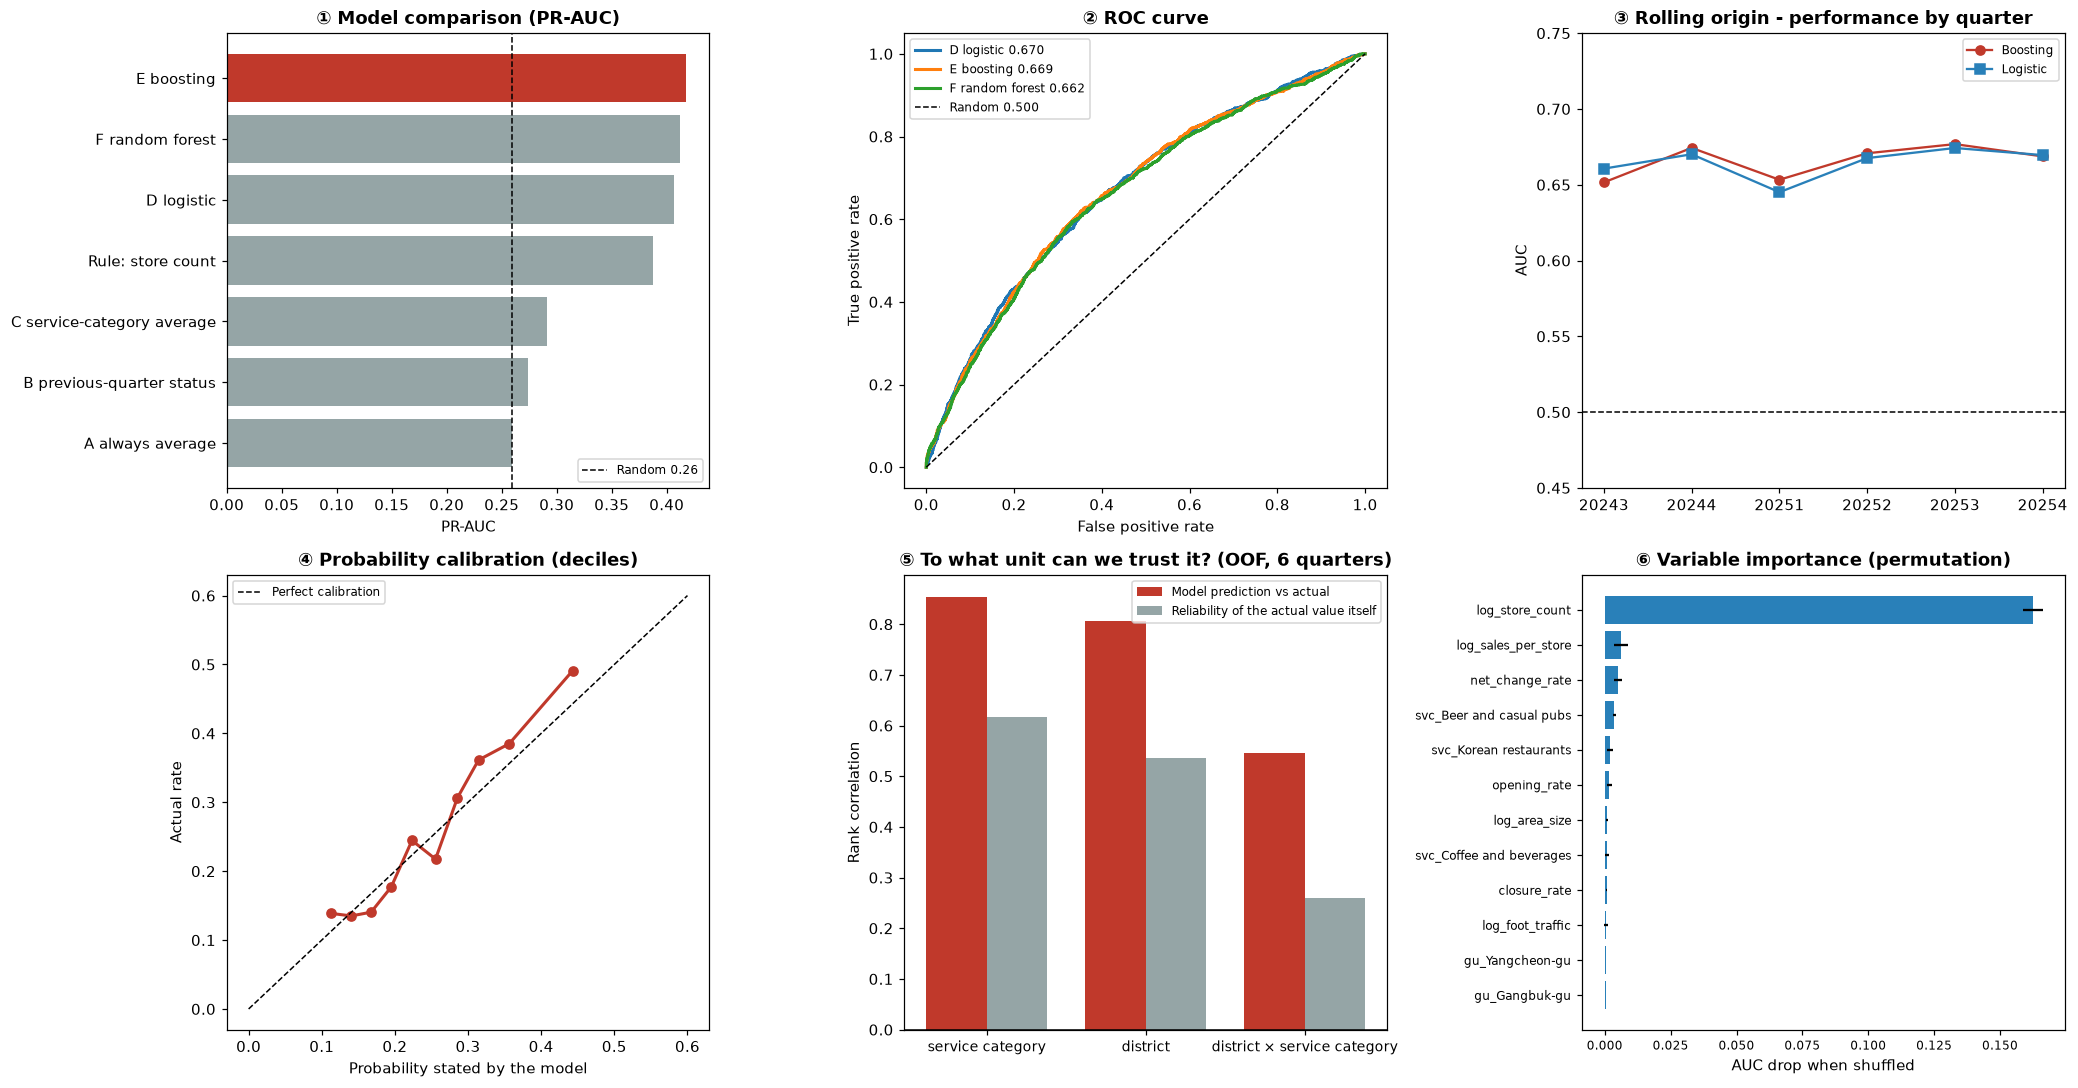

In [18]:
fig, ax = plt.subplots(2, 3, figsize=(19, 10))

# ① Model comparison
b = board.sort_values("PR-AUC")
cols = ["#c0392b" if i == BEST else "#95a5a6" for i in b.index]
ax[0,0].barh(b.index, b["PR-AUC"], color=cols)
ax[0,0].axvline(yva.mean(), ls="--", c="k", lw=1, label=f"Random {yva.mean():.2f}")
ax[0,0].set_xlabel("PR-AUC"); ax[0,0].legend(fontsize=8)
ax[0,0].set_title("① Model comparison (PR-AUC)", weight="bold")

# ② ROC
for nm, p in preds.items():
    fpr, tpr, _ = roc_curve(yva, p)
    ax[0,1].plot(fpr, tpr, lw=2, label=f"{nm} {roc_auc_score(yva,p):.3f}")
ax[0,1].plot([0,1],[0,1], ls="--", c="k", lw=1, label="Random 0.500")
ax[0,1].set_xlabel("False positive rate"); ax[0,1].set_ylabel("True positive rate")
ax[0,1].set_title("② ROC curve", weight="bold"); ax[0,1].legend(fontsize=8)

# ③ Rolling origin
ax[0,2].plot(rollf["valid_quarter"].astype(str), rollf["auc_boosting"], marker="o", label="Boosting", color="#c0392b")
ax[0,2].plot(rollf["valid_quarter"].astype(str), rollf["auc_logistic"], marker="s", label="Logistic", color="#2980b9")
ax[0,2].axhline(0.5, ls="--", c="k", lw=1)
ax[0,2].set_ylim(0.45, 0.75); ax[0,2].set_ylabel("AUC")
ax[0,2].set_title("③ Rolling origin - performance by quarter", weight="bold"); ax[0,2].legend(fontsize=8)

# ④ Calibration
ax[1,0].plot(cal["mean_pred"], cal["actual_rate"], marker="o", color="#c0392b", lw=2)
ax[1,0].plot([0,0.6],[0,0.6], ls="--", c="k", lw=1, label="Perfect calibration")
ax[1,0].set_xlabel("Probability stated by the model"); ax[1,0].set_ylabel("Actual rate")
ax[1,0].set_title("④ Probability calibration (deciles)", weight="bold"); ax[1,0].legend(fontsize=8)

# ⑤ Trustworthy unit
lv = pd.DataFrame(rows_lv)
x = np.arange(len(lv)); w = 0.38
ax[1,1].bar(x - w/2, lv["rank_corr_pred_actual"], w, label="Model prediction vs actual", color="#c0392b")
ax[1,1].bar(x + w/2, lv["target_split_half_reliability"], w, label="Reliability of the actual value itself", color="#95a5a6")
ax[1,1].set_xticks(x); ax[1,1].set_xticklabels(lv["unit"], fontsize=9)
ax[1,1].set_ylabel("Rank correlation"); ax[1,1].axhline(0, c="k", lw=1)
ax[1,1].set_title("⑤ To what unit can we trust it? (OOF, 6 quarters)", weight="bold")
ax[1,1].legend(fontsize=8)

# ⑥ Variable importance
t = imp.head(12).iloc[::-1]
ax[1,2].barh(t["feature"], t["auc_drop"], xerr=t["std"], color="#2980b9")
ax[1,2].set_xlabel("AUC drop when shuffled"); ax[1,2].tick_params(labelsize=8)
ax[1,2].set_title("⑥ Variable importance (permutation)", weight="bold")

plt.tight_layout()
plt.savefig(FIG / "step8_predict.png", dpi=130)
plt.show()

## 8-10. Save the model

STEP 9 loads and uses it as is. **The feature column order and imputation values must be saved together** so the design matrix does not drift at prediction time.

In [19]:
bundle = {
    "model": model_best,
    "model_name": BEST,
    "columns": COLS,
    "median": MED,
    "needs_impute": BEST != "E boosting",
    "train_quarters": TRAIN_QUARTERS,
    "valid_quarter": VALID_Q,
    "valid_metrics": board.loc[BEST].to_dict(),
    "rolling_auc_mean": float(rollf["auc_boosting"].mean()),
}
with open(PROC / "08_model.pkl", "wb") as f:
    pickle.dump(bundle, f)

board.to_csv(OUT / "pred_leaderboard.csv", encoding="utf-8-sig")
rollf.to_csv(OUT / "pred_rolling.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(rows_lv).to_csv(OUT / "pred_reliability.csv", index=False, encoding="utf-8-sig")
oof.to_pickle(PROC / "08_oof.pkl")

print(f"[Saved] 08_model.pkl   ({BEST}, {len(COLS)} features)")
print(f"[Saved] 08_oof.pkl     {oof.shape}")
print(f"[Saved] outputs/pred_leaderboard.csv, pred_rolling.csv, pred_reliability.csv")
print(f"[Saved] figures/step8_predict.png\n")

print("── To hand over to STEP 9 ─────────────────")
print(f"  Selected model   : {BEST}")
print(f"  [Validation values] AUC {board.loc[BEST,'AUC']:.3f} / PR-AUC {board.loc[BEST,'PR-AUC']:.3f} "
      f"(random {yva.mean():.3f}) / Brier {board.loc[BEST,'Brier']:.3f}")
print( "     ⚠️ The model was chosen by looking at this table, so these values are biased optimistically.")
print(f"  [Unbiased estimate] rolling AUC {rollf['auc_boosting'].mean():.3f} ± {rollf['auc_boosting'].std():.3f} "
      f"({len(rollf)} quarters)  <- use this value in reporting")
print(f"  [Practical performance] precision of the top {topk.index[0]} cells {topk['model_precision'].iloc[0]:.3f} "
      f"(store-count rule {topk['store_count_precision'].iloc[0]:.3f}, list overlap {topk['list_overlap'].iloc[0]:.0%})")
print(f"  [External baseline] Seoul commercial-area change indicator HL  Lift {prec_hl/base_rate:.3f}")
print(f"  Trustworthy unit   : service-category and district rankings are reliable; district × service category needs probability + sample size shown together")

[Saved] 08_model.pkl   (E boosting, 51 features)
[Saved] 08_oof.pkl     (33223, 7)
[Saved] outputs/pred_leaderboard.csv, pred_rolling.csv, pred_reliability.csv
[Saved] figures/step8_predict.png

── To hand over to STEP 9 ─────────────────
  Selected model   : E boosting
  [Validation values] AUC 0.669 / PR-AUC 0.418 (random 0.260) / Brier 0.179
     ⚠️ The model was chosen by looking at this table, so these values are biased optimistically.
  [Unbiased estimate] rolling AUC 0.666 ± 0.011 (6 quarters)  <- use this value in reporting
  [Practical performance] precision of the top 50 cells 0.780 (store-count rule 0.380, list overlap 4%)
  [External baseline] Seoul commercial-area change indicator HL  Lift 0.937
  Trustworthy unit   : service-category and district rankings are reliable; district × service category needs probability + sample size shown together


---

## To do in STEP 9

- Score `03_score.pkl` (feature quarter 20261) to produce the **20262 prediction**
- **District × service category** ranking table - shown together with probability, sample size and uncertainty
- Combinations with thin cells are dropped from the ranking, and that fact is stated explicitly
- Place it alongside the H2 result - "once size is matched, Korean restaurants are safe" (causal) vs "in reality Korean restaurants rank high in risk" (prediction) are not a contradiction but answers to different questions